In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import os

filepath = os.getcwd()
characteristics_path = os.path.join(filepath, 'characteristics.csv')
us_equity_filepath = os.path.join(filepath, 'us_equity.csv')
print(us_equity_filepath)


/Users/ryaneng/Desktop/Systemic/QTAB/factor-modeling/us_equity.csv


In [3]:
characteristics_df = pd.read_csv(characteristics_path)
metrics = characteristics_df['abr_jkp'].unique()
metrics = [metric for metric in metrics if pd.notna(metric)]
metric_df = characteristics_df[pd.notna(characteristics_df['abr_jkp'])][['abr_jkp', 'name_new']]

In [4]:
metric_df

,abr_jkp,name_new
0,niq_su,Standardized earnings surprise
3,ret_6_1,Price momentum t-6 to t-1
4,ret_12_1,Price momentum t-12 to t-1
6,saleq_su,Standardized Revenue surprise
7,tax_gr1a,Tax expense surprise
...,...,...
250,mispricing_mgmt,Mispricing factor: Management
251,qmj,Quality minus Junk: Composite
252,qmj_prof,Quality minus Junk: Profitability
253,qmj_growth,Quality minus Junk: Growth


In [5]:
chunksize=5000
all_dfs = []   
us_df = pd.DataFrame() 
for chunk in pd.read_csv(us_equity_filepath, index_col=0, chunksize=chunksize):
    all_dfs.append(chunk)  
us_df = pd.concat(all_dfs)

In [6]:
us_df.index = pd.to_datetime(us_df.index)

In [7]:
us_df[['gvkey', 'permno']].isnull().all(axis=1).sum()

np.int64(0)

In [8]:
len(us_df.gvkey.unique())

25797

In [9]:
columns = us_df.columns

In [ ]:
#print all columns




In [10]:
cleaned_us_df = us_df
cleaned_us_df['gvkey'] = cleaned_us_df['gvkey'].fillna(-1)
cleaned_us_df['permno'] = cleaned_us_df['permno'].fillna(-1)

In [11]:
print(len(cleaned_us_df.columns))

158


In [12]:
grouped_df = cleaned_us_df.groupby(['gvkey', 'permno'], dropna=False)

In [13]:
group_keys = list(grouped_df.groups.keys())
group = grouped_df.get_group(group_keys[0])
group.head(10)

,id,gvkey,permno,size_grp,me,niq_su,ret_6_1,ret_12_1,saleq_su,tax_gr1a,...,rmax5_rvol_21d,ni_be,ocf_at,ocf_at_chg1,mispricing_perf,mispricing_mgmt,qmj,qmj_prof,qmj_growth,qmj_safety
eom,,,,,,,,,,,,,,,,,,,,,
1925-12-31,10006.0,-1.0,10006.0,large,65.400,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-01-31,10006.0,-1.0,10006.0,large,66.150,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-02-28,10006.0,-1.0,10006.0,large,61.425,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-03-31,10006.0,-1.0,10006.0,large,57.900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-04-30,10006.0,-1.0,10006.0,large,56.400,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-05-31,10006.0,-1.0,10006.0,large,57.750,NaN,NaN,NaN,NaN,NaN,...,0.990039,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-06-30,10006.0,-1.0,10006.0,large,59.400,NaN,-0.084394,NaN,NaN,NaN,...,1.299831,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-07-31,10006.0,-1.0,10006.0,NaN,NaN,NaN,-0.074266,NaN,NaN,NaN,...,0.895480,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1926-08-31,10006.0,-1.0,10006.0,large,60.600,NaN,NaN,NaN,NaN,NaN,...,0.807510,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
later_than_2000 = grouped_df.filter(lambda x: x.index.min() > pd.to_datetime(str(20000101)))

In [ ]:
later_than_2000.head(10)

,id,gvkey,permno,size_grp,me,niq_su,ret_6_1,ret_12_1,saleq_su,tax_gr1a,...,rmax5_rvol_21d,ni_be,ocf_at,ocf_at_chg1,mispricing_perf,mispricing_mgmt,qmj,qmj_prof,qmj_growth,qmj_safety
eom,,,,,,,,,,,,,,,,,,,,,
2000-01-31,87520.0,127575.0,87520.0,micro,128.430000,NaN,NaN,NaN,NaN,NaN,...,NaN,0.113946,0.152734,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-31,101241801.0,12418.0,-1.0,small,739.963000,2.053811,NaN,NaN,1.336986,0.001501,...,NaN,NaN,0.077496,0.043627,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-31,87558.0,-1.0,87558.0,nano,11.385000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-31,87532.0,-1.0,87532.0,nano,14.674000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-31,87559.0,128740.0,87559.0,small,325.050250,NaN,NaN,NaN,NaN,NaN,...,NaN,-0.441130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-31,89317.0,3410.0,89317.0,micro,103.644000,-0.474462,0.036097,0.031125,-5.860619,0.000000,...,0.553129,0.116012,0.018692,0.011244,0.394426,0.390731,-0.191025,-0.727314,1.454475,-0.783573
2000-01-31,87557.0,124934.0,87557.0,nano,18.022500,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.292035,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-31,87567.0,127674.0,87567.0,micro,26.408125,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-31,87576.0,128620.0,87576.0,micro,141.529313,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-0.119562,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df = later_than_2000[(later_than_2000['gvkey'] == 8762) & (later_than_2000['permno'] == 18163)]

In [ ]:
df.head(10)

,id,gvkey,permno,size_grp,me,niq_su,ret_6_1,ret_12_1,saleq_su,tax_gr1a,...,rmax5_rvol_21d,ni_be,ocf_at,ocf_at_chg1,mispricing_perf,mispricing_mgmt,qmj,qmj_prof,qmj_growth,qmj_safety
eom,,,,,,,,,,,,,,,,,,,,,


In [ ]:
later_than_2000.index.max()

Timestamp('2024-03-31 00:00:00')

In [ ]:
len(later_than_2000['permno'].unique())

7488

In [ ]:
later_than_2000

618056

In [ ]:
val = metric_df[(metric_df['abr_jkp'] == 'niq_su') | (metric_df['abr_jkp'] == 'tax_gr1a')]
val

,abr_jkp,name_new
0,niq_su,Standardized earnings surprise
7,tax_gr1a,Tax expense surprise


In [ ]:
max_date = later_than_2000.index.max()
unique_values = later_than_2000.loc[max_date, 'niq_su'].unique()
print(len(unique_values))

3684


In [ ]:
len(later_than_2000.loc[max_date])

4586

In [ ]:
name = metric_df[characteristics_df.name_new  == 'Standardized Revenue surprise']
print(name)

    abr_jkp                       name_new
6  saleq_su  Standardized Revenue surprise


/var/folders/5w/_sx0pyps50s6zzsjl55lmt340000gn/T/ipykernel_69379/3381803383.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  name = metric_df[characteristics_df.name_new  == 'Standardized Revenue surprise']


In [ ]:
momentum_sales = later_than_2000['saleq_su']

<Axes: xlabel='saleq_su', ylabel='Count'>

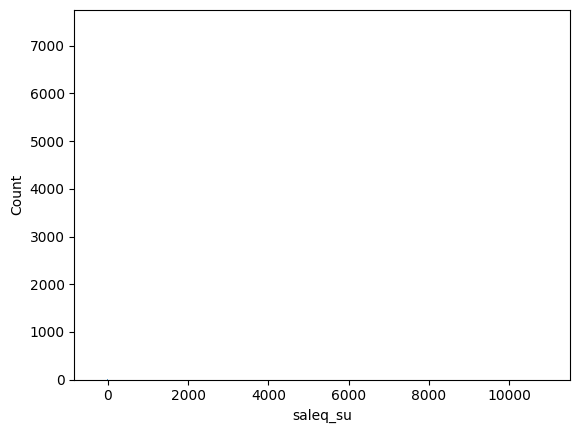

In [ ]:
import seaborn as sns

sns.histplot(momentum_sales)

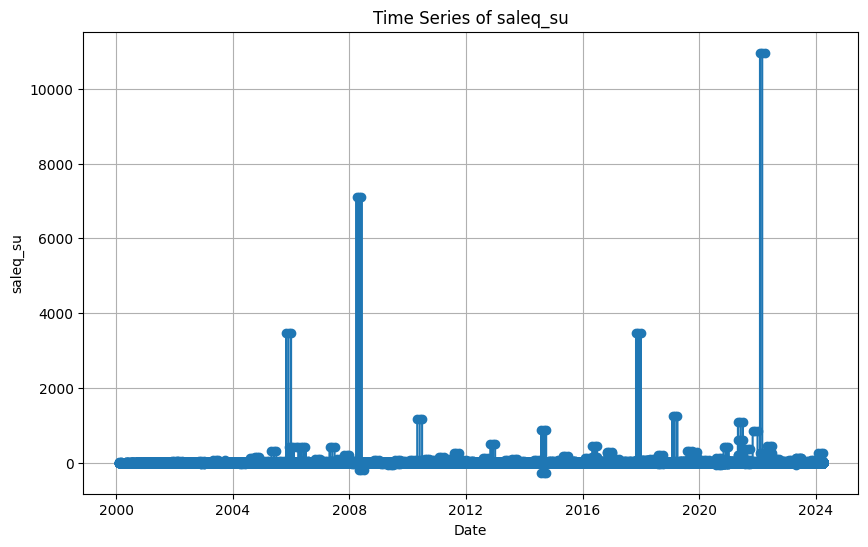

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(later_than_2000.index, later_than_2000['saleq_su'], marker='o', linestyle='-')
plt.title('Time Series of saleq_su')
plt.xlabel('Date')
plt.ylabel('saleq_su')
plt.grid(True)
plt.show()